# <center> Линейная алгебра в контексте линейных методов. Практика.

## <center> Прогнозирование выработки газа на скважинах.

## Постановка задачи

У Василия, основателя компании «Газ-Таз-Ваз-Нефть», дела идут в гору: у него уже функционирует 200 скважин для добычи газа. В этом году он открывает 30 новых скважин. Однако в целях оптимизации расходов и повышения дохода Василию необходимо оценить, сколько денег будет приносить ему каждая из скважин, а также понять, какие факторы (параметры скважин) потенциально сильнее всего повлияют на объём добычи газа. Для этого Василий решил нанять вас как специалиста в области Data Science.

Василий представляет вам набор данных о добыче газа на своих скважинах. Файл с данными вы можете скачать на платформе.

**Признаки в данных:**

* Well — идентификатор скважины;
* Por — пористость скважины (%);
* Perm — проницаемость скважины;
* AI — акустический импеданс ($кг/м^2 * 10^6$);
* Brittle — коэффициент хрупкости скважины (%);
* TOC — общий органический углерод (%);
* VR — коэффициент отражения витринита (%);
* Prod — добыча газа в сутки (млн. кубических футов).

**Ваша задача** — построить регрессионную модель, которая прогнозирует выработку газа на скважине (целевой признак — Prod) на основе остальных характеристик скважины, и проинтерпретировать результаты вашей модели.

Разделим задачу на две части:
* В первой мы построим простейшую модель линейной регрессии, проанализируем результаты её работы и выберем наиболее значимые факторы для прогнозирования.
* Во второй мы займёмся построением модели полиномиальной регрессии с регуляризацией и посмотрим на итоговые результаты моделирования.


Импортируем необходимые библиотеки:

In [155]:
# Импорт библиотек
import numpy as np # для работы с массивами
import pandas as pd # для работы с DataFrame 
import seaborn as sns # библиотека для визуализации статистических данных
import matplotlib.pyplot as plt # для построения графиков

%matplotlib inline

Прочитаем исходные данные:

In [156]:
data = pd.read_csv('data/unconv.csv')
data.head()

,Well,Por,Perm,AI,Brittle,TOC,VR,Prod
0,1,12.08,2.92,2.80,81.40,1.16,2.31,4165.196191
1,2,12.38,3.53,3.22,46.17,0.89,1.88,3561.146205
2,3,14.02,2.59,4.01,72.80,0.89,2.72,4284.348574
3,4,17.67,6.75,2.63,39.81,1.08,1.88,5098.680869
4,5,17.52,4.57,3.18,10.94,1.51,1.90,3406.132832


## Практика: линейная регрессия по методу наименьших квадратов

Для начала построим простейшую модель линейной регрессии, проанализируем результаты её работы и выберем наиболее значимые факторы для прогнозирования.

В первой части вам предстоит выполнить задания 5.0–5.6. Максимальное количество баллов, которое можно получить, — 9.

### Задание 5.0. (не оценивается)

Проведите небольшой разведывательный анализ, чтобы поближе познакомиться с исходными данными. Постройте несколько визуализаций, которые помогут вам понять, как устроены исходные признаки, а также смогут продемонстрировать взаимосвязь факторов. 

Сделайте промежуточные выводы из проведённого разведывательного анализа.

,Well,Por,Perm,AI,Brittle,TOC,VR,Prod
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,14.991150,4.330750,2.968850,48.161950,0.990450,1.964300,4311.219852
std,57.879185,2.971176,1.731014,0.566885,14.129455,0.481588,0.300827,992.038414
min,1.000000,6.550000,1.130000,1.280000,10.940000,-0.190000,0.930000,2107.139414
25%,50.750000,12.912500,3.122500,2.547500,37.755000,0.617500,1.770000,3618.064513
50%,100.500000,15.070000,4.035000,2.955000,49.510000,1.030000,1.960000,4284.687348
75%,150.250000,17.402500,5.287500,3.345000,58.262500,1.350000,2.142500,5086.089761
max,200.000000,23.550000,9.870000,4.630000,84.330000,2.180000,2.870000,6662.622385


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Well     200 non-null    int64  
 1   Por      200 non-null    float64
 2   Perm     200 non-null    float64
 3   AI       200 non-null    float64
 4   Brittle  200 non-null    float64
 5   TOC      200 non-null    float64
 6   VR       200 non-null    float64
 7   Prod     200 non-null    float64
dtypes: float64(7), int64(1)
memory usage: 12.6 KB


None

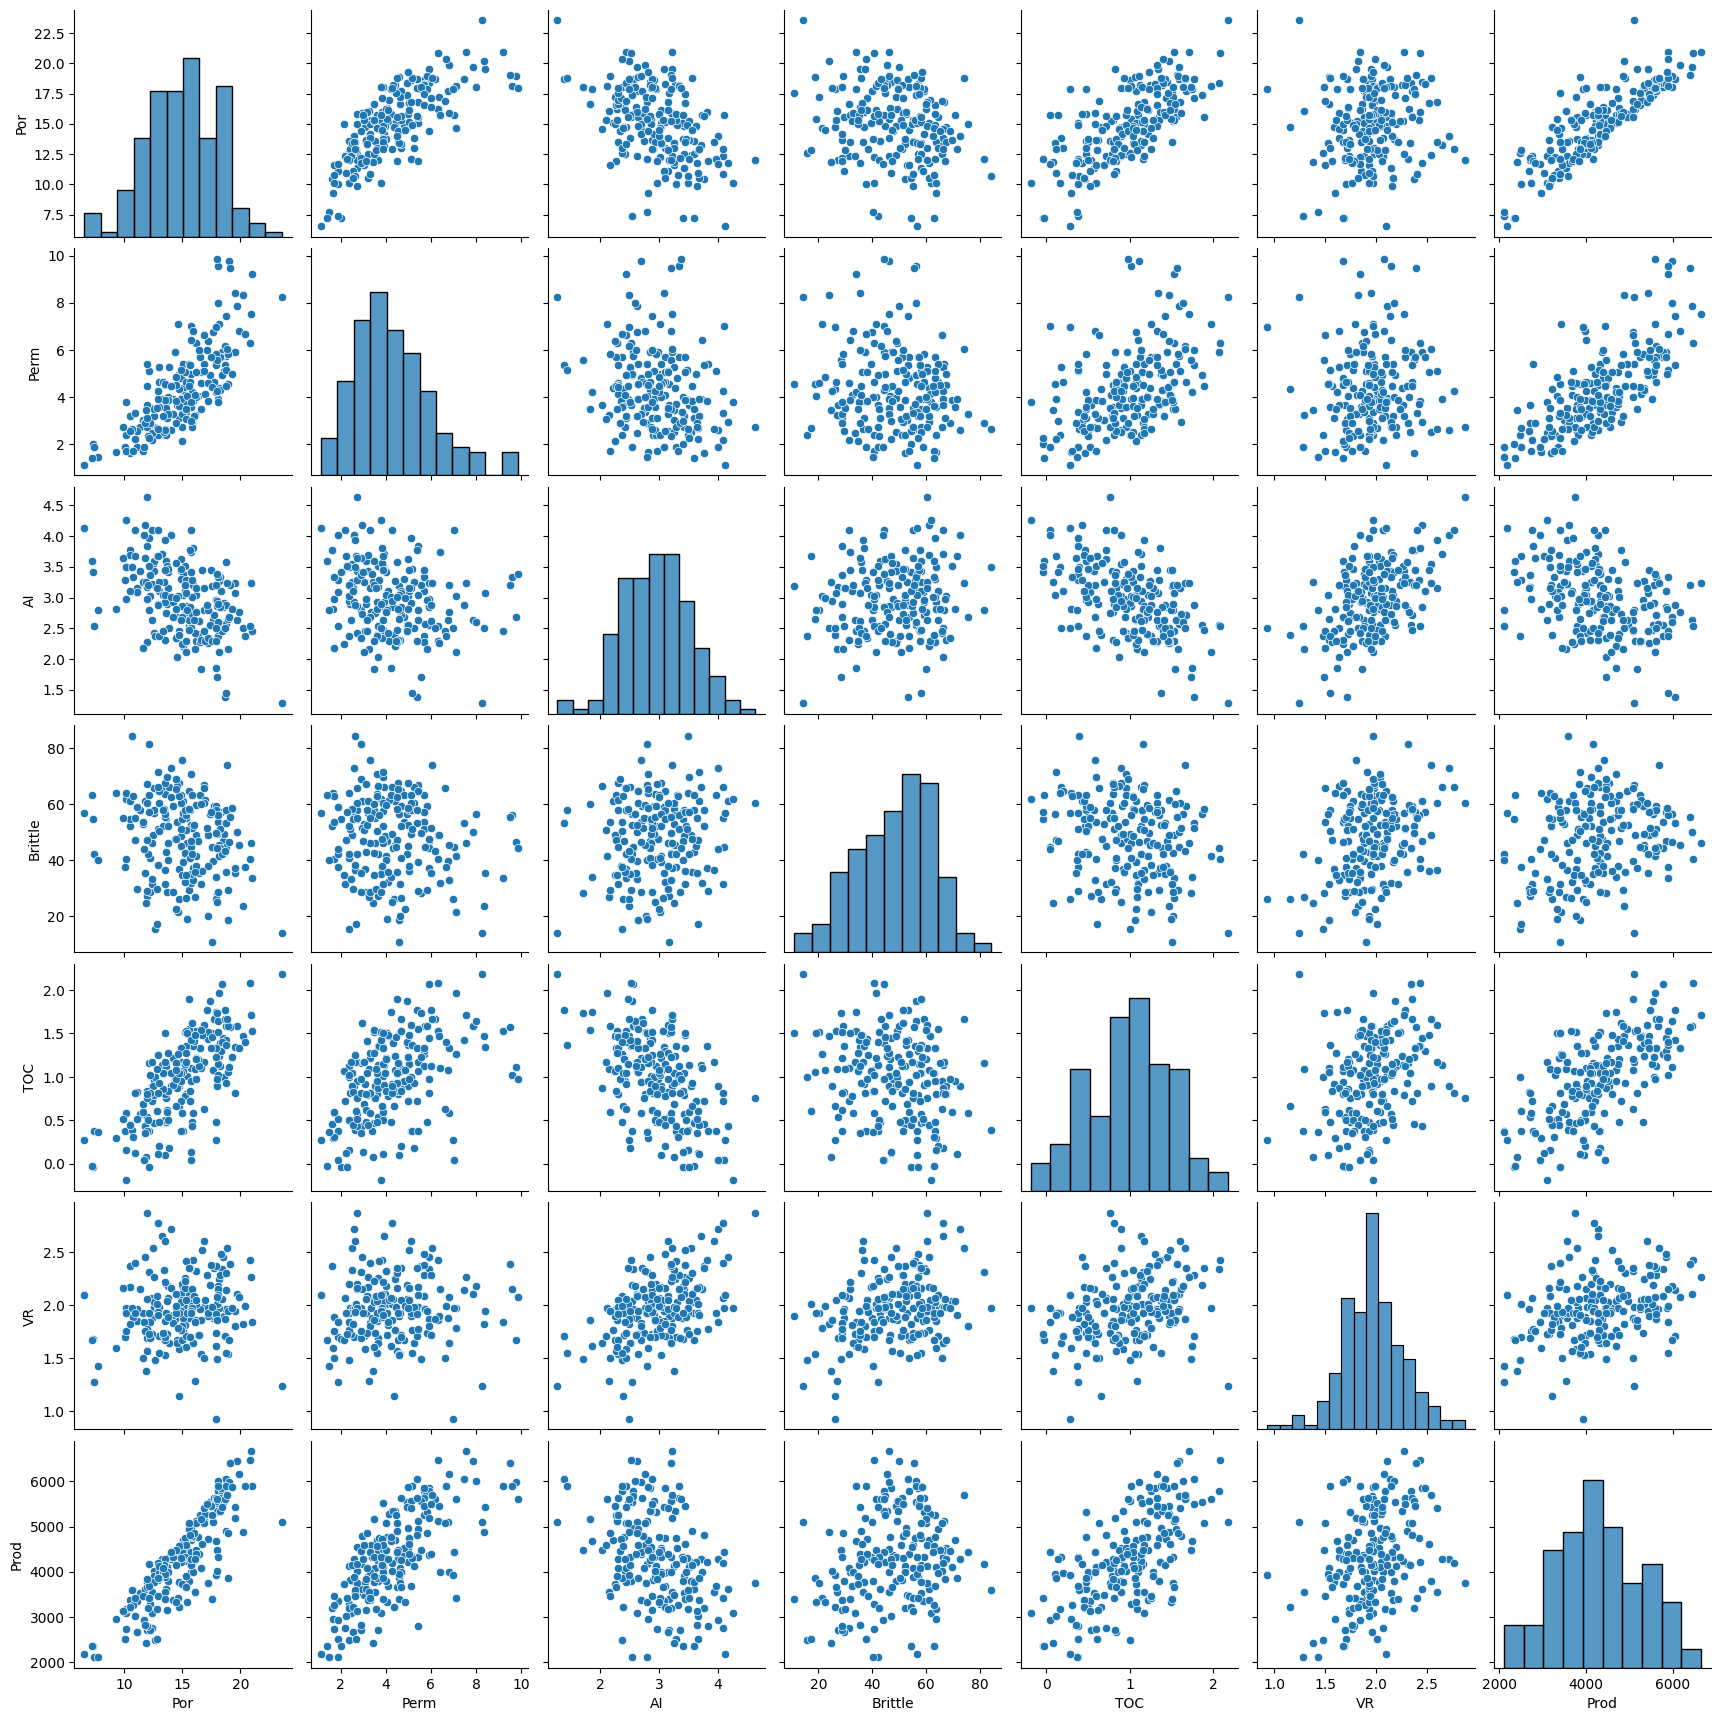

In [157]:
# Ваш код здесь
display(data.describe()) # выведем статистические показатели для всех признаков
display(data.info()) # проверим количество и формат записей
sns.pairplot(data.drop(['Well'], axis=1)) # Построим графики распределения и зависимостей для числовых признаков

### Задание 5.1. (2 балла)

Постройте корреляционную матрицу факторов, включив в неё целевой признак. 

Для наглядности визуализируйте полученную матрицу с помощью тепловой карты. 

**Примечание.** *Для визуализации вы можете использовать любую из знакомых вам библиотек.*

На основе построенной корреляционной матрицы ответьте на следующий вопрос:

* Какие факторы сильнее всего коррелируют с целевой переменной?

Вычислите ранг и определитель полученной матрицы корреляций и приведите развёрнутые ответы на следующие вопросы:
* Является ли корреляционная матрица плохо обусловенной (близок ли её опредитель к нулю)?
* Что вы можете сказать о наличии коллинераности/мультиколлинеарности в данных? 
* Применима ли в данном случае модель классической линейной регрессии по методу наименьших квадратов и почему? 

**Критерии оценивания:**
- Задание выполнено верно, учтены все условия (**2 балла**): 
    * приведён код для расчёта корреляционной матрицы;
    * приведён код для визуализации корреляционной матрицы в виде тепловой карты;
    * рассчитаны ранг и определитель корреляционной матрицы;
    * предоставлены обоснованные ответы на все поставленные вопросы. 

- Задание выполнено верно, но не учтено одно условие (**1 балл**).
- Задание выполнено неверно, не учтено несколько условий (**0 баллов**).

Ранг корреляционной матрицы:  8
Определитель корреляционной матрицы:  0.0007299388072652069


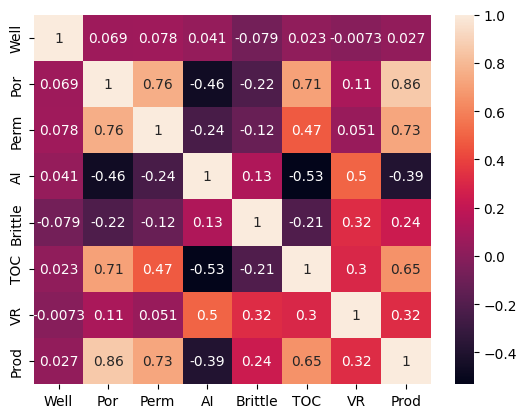

In [158]:
# Ваш код здесь
corr = data.corr() # создадим корреляционную матрицу
sns.heatmap(corr, annot=True) # визуализируем матрицу кореляций при помощи тепловой карты

print("Ранг корреляционной матрицы: ", np.linalg.matrix_rank(corr)) # ранг
print("Определитель корреляционной матрицы: ", np.linalg.det(corr)) # определитель

> *Ваши выводы здесь*  
По корреляционной матрице видно, что с суточной добычей 'Prod' сильнее всего коррелируются пористость скважины 'Por', проницаемость скважины 'Perm', и общий органический углерод 'TOC'.  
Определитель матрицы корреляций близок к нулю, значит матрица плохо обусловлена. Присутствует заметная мультиколинеарность признаков 'Perm'-'Por', 'AI'-'TOC' и 'TOC'-'Por'. Применение в данном случае линейной регрессии может повлечь неустойчивость коэффициентов и, следовательно, плохую интрепертируемость оных.


### Задание 5.2. (2 балла)

Создайте матрицу наблюдений `X` и вектор правильных ответов `y`. В качестве факторов для матрицы наблюдений возьмите все имеющиеся в данных признаки. 

Постройте модель линейной регрессии по методу наименьших квадратов. Для этого воспользуйтесь матричной формулой МНК и инструментарием библиотеки numpy. 

Выведите на экран полученные оценки коэффициентов модели, округлённые до целого.

Приведите подробные выводы по полученным результатам, ответив на следующие вопросы:
* Есть ли в ваших данных признаки, которые, согласно модели, можно назвать неинформативными, то есть они не оказывают влияния на целевую переменную или оказывают шумовое влияние?
* Приведите интерпретацию нескольких (двух или трёх) коэффициентов полученной модели линейной регрессии.


**Критерии оценивания:**
- Задание выполнено верно, учтены все условия (**2 балла**): 
    * приведён код для нахождения параметров модели линейной регрессии с помощью матричной формулы МНК;
    * на основе полученных параметров даны верные ответы на поставленные вопросы;
    * приведена корректная интерпретация нескольких коэффициентов полученной модели линейной регрессии.

- Задание выполнено верно, но не учтено одно из условий (**1 балл**).
- Задание выполнено неверно, не учтено несколько условий (**0 баллов**).

In [159]:
# Ваш код здесь

X = np.array(data.drop(['Prod'], axis=1)) # создаём матрицу наблюдений
X = np.insert(X, 0, np.ones(200), axis=1) # добавляем интерсепт
y = np.array(data['Prod']) # матрица целевого признака

w = np.linalg.inv(X.T@X) @ X.T @ y # вычисляем коэффециенты линейной регресси по методу МНК

print("Округлённые коэффициенты линейной регрессии для всех признаков:", np.round(w)) 

Округлённые коэффициенты линейной регрессии для всех признаков: [-1232.     0.   230.   116.  -365.    25.   -78.   785.]


> *Ваши выводы здесь*  
Явно стоило исключить признак идентификатор скважины 'Well', что нам и показывает значение соответствующего коэффициента. Коэффициент хрупкости скважины 'Brittle' относительно невелик, что и следовало из матрицы корреляций(корреляция данного признака с целевым минимальна, за исключением неинформативного идентификатора скважины).     
Наибольшее влияние на прогноз оказывает признак 'VR' - коэффициент отложения витринита, чем больше процент - тем выше суточная добыча. Обратный, но так же весомый эффект имеет признак 'AI', чем выше значение акустического импеданса, тем ниже суточная добыча газа на данной скважине.

### Задание 5.3. (1 балл)

Теперь потренируемся строить предсказание для наблюдений целевой переменной. 

**а)** Постройте прогноз выработки газа для скважины со следующими параметрами:

```python
{
    'Well': 106.0,
    'Por': 15.32,
    'Perm': 3.71,
    'AI': 3.29,
    'Brittle': 55.99,
    'TOC': 1.35,
    'VR': 2.42
 }
```

Рассчитайте абсолютную ошибку построенного вами прогноза для предложенной скважины (в миллионах кубических футов в день), если известно, что на этой скважине производится `4748.315024` миллионов кубических футов газа в день. 

**б)** Постройте прогноз выработки газа для всех скважин из обучающего набора данных. Выберите метрику, по которой вы будете оценивать качество регрессионных моделей и сравнивать их между собой (можно использовать несколько метрик, но не более двух).

Рассчитайте значение выбранной метрики для вашей модели. Приведите интерпретацию полученного результата. 

**Критерии оценивания:**
- Задание выполнено верно, учтены все условия (**1 балл**): 
    * приведён код для построения прогноза выработки газа на указанной скважине и рассчитана абсолютная ошибка прогноза для этой скважины;
    * выбрана корректная для поставленной задачи метрика (или метрики) оценки качества модели и приведён код для расчёта этой метрики на всём обучающем наборе данных;
    * приведена корректная интерпретация полученного результата.

- Задание выполнено верно, но не учтено одно из условий, или задание выполнено неверно (**0 баллов**).

In [160]:
# Ваш код здесь
from sklearn import metrics


data_1 = pd.DataFrame.from_dict({
    'Well': [106.0],
    'Por': [15.32],
    'Perm': [3.71],
    'AI': [3.29],
    'Brittle': [55.99],
    'TOC': [1.35],
    'VR': [2.42]
    })

X_106 = np.array(data_1)
X_106 = np.insert(X_106, 0, np.ones(1), axis=1) # добавляем интерсепт

y_106 = w @ X_106.T # прогноз с ранее полученными коэффициентами по МНК для одной скважины
print("Прогноз суточной добычи скважины 106:", y_106) 

print("Абсолютная ошибка прогноза для скважины 106:",  4748.315024 - y_106[0], "(млн. куб. футов)")

y_pred = w @ X.T # прогноз для всех скважин

print("Средняя абсолютная ошибка модели MAPE: {:.2f} %".format(metrics.mean_absolute_percentage_error(y, y_pred) * 100))
print("Коэффициент детерминации R2 модели: {:.3f}".format(metrics.r2_score(y, y_pred)))


Прогноз суточной добычи скважины 106: [4723.06405371]
Абсолютная ошибка прогноза для скважины 106: 25.250970292718193 (млн. куб. футов)
Средняя абсолютная ошибка модели MAPE: 3.63 %
Коэффициент детерминации R2 модели: 0.960


> *Ваши выводы здесь*  
Средняя абсолютная ошибка для модели 3,6% и высокий коэффициент детерминации говорят нам о том, что модель хорошо предсказывает суточную добычу скважины на данном наборе данных.


### Задание 5.4. (1 балл)

Настало время анализа построенной модели. Посмотрите на коэффициенты и сравните их знаки со значениями выборочных корреляций между целевым признаком и факторами, которые вы нашли ранее.

Дайте развёрнутые ответы на следующие вопросы:

* Есть ли в вашей модели фактор, при котором коэффициент в модели линейной регрессии противоречит соответствующему коэффициенту корреляции? Например, корреляция говорит, что зависимость между фактором и целевой переменной прямая, а модель говорит обратное. Если таких факторов несколько, укажите их все.
* Как вы считаете, с чем связано полученное противоречие результатов?

**Критерии оценивания:**

- Задание выполнено верно, даны корректные развёрнутые ответы на все поставленные в задании вопросы (**1 балл**). 

- Задание выполнено неверно, даны некорректные ответы на один или несколько поставленных в задании вопросов (**0 баллов**).

> *Ваши выводы здесь*  
В матрице корреляций у признака "TOC - обший органический углерод" прямая корреляция с целевым признаком. При моделировании же мы получили отрицательный коэффициент для этого признака, по причине плохой обусловленности данных вследствие мультиколлениарности и несоответствия размерности признаков. В таких случаях коэффициенты регрессии неустойчивы и плохо интерпертируемы (не всегда отображают реальную картину зависимостей). 

### Задание 5.5. (2 балла)

* Исключите из данных сильно коррелированные между собой факторы. Под сильной корреляцией в данной задаче будем понимать значения выше `0.7`.

Выбирая, какой из коррелированных факторов оставить, руководствуйтесь коэффициентом корреляции с целевой переменной: оставляйте тот фактор, который больше всего коррелирует с целевой переменной (объёмом добычи газа).

* Также исключите из данных факторы, для которых корреляция с целевой переменной меньше `0.05`.

Постройте модель линейной регрессии на обновлённых после удаления факторов данных по методу наименьших квадратов. Для этого используйте матричную формулу и библиотеку numpy. Выведите значение полученных коэффициентов, округлённых до целого.

Сделайте прогноз для всего обучающего набора данных и рассчитайте выбранную вами ранее метрику (или метрики). 

Дайте подробные ответы на следующие вопросы:

* Приведите интерпретацию нескольких полученных коэффициентов (двух или трёх). Сравните их значения с полученными ранее.
* Приведите интерпретацию полученных значений метрик. Сравните их значения с полученными ранее. 
* Удалось ли вам побороть противоречие коэффициентов линейной регрессии и коэффициентов корреляции?

**Критерии оценивания:**
- Задание выполнено верно, учтены все условия (**2 балла**): 
    * отобраны верные факторы;
    * на основе отобранных факторов построена модель линейной регрессии с помощью матричной формулы МНК и найдены параметры модели, соответствующие каждому из факторов;
    * построен прогноз для всего обучающего набора данных и рассчитано значение метрики (метрика должна быть выбрана корректно);
    * даны ответы на все поставленные в задании вопросы.

- Задание выполнено верно, но не учтено одно из условий (**1 балл**).
- Задание выполнено верно, не учтено несколько из условий (**0 баллов**).

Округлённые коэффициенты линейной регрессии [-1835.   293.  -200.    28.   517.]
Средняя абсолютная ошибка модели: 4.04 %
Коэффициент детерминации R2 модели: 0.945


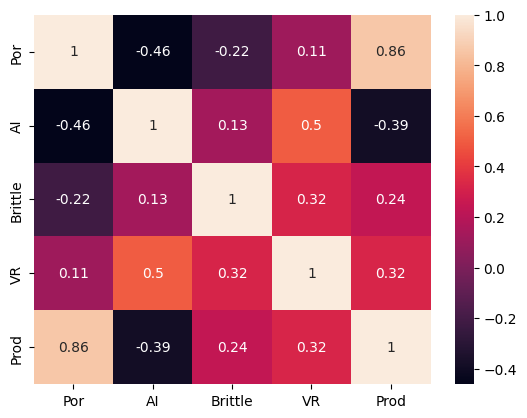

In [161]:
# Ваш код здесь

exept_list = ['Well', 'Perm', 'TOC']
data_new = data.drop(exept_list, axis=1)

X_new = np.array(data_new.drop('Prod', axis=1)) # создаём матрицу наблюдений
X_new = np.insert(X_new, 0, np.ones(200), axis=1) # добавляем интерсепт

w_new = np.linalg.inv(X_new.T@X_new) @ X_new.T @ y # вычисляем коэффециенты линейной регресси по методу МНК

sns.heatmap(data_new.corr(), annot=True)

print("Округлённые коэффициенты линейной регрессии", np.round(w_new)) 

y_pred_new = w_new @ X_new.T # прогноз для всех скважин

print("Средняя абсолютная ошибка модели: {:.2f} %". format(metrics.mean_absolute_percentage_error(y, y_pred_new) * 100))
print("Коэффициент детерминации R2 модели: {:.3f}".format(metrics.r2_score(y, y_pred_new)))

> *Ваши выводы здесь*  
По прежнему наибольшее положительное влияние на величину суточной добычи газа оказывает признак "'VR' - коэффициент отложения витринита". Акустический импеданс 'AI' в свою очередь остался фактором занижающим величину целевого признака - чем выше значение акустического импеданса, тем ниже суточная добыча газа на данной скважине.  
Метрики по сравнению с метриками прошлой модели незначительно ухудшились, но это не значит, что модель хуже, так как метрики считались на тех же данных что и строилась модель(первая модель переобучена), а вот на новых данных модель покажет лучшие результаты, так как мы изавились от мультиколениарных признаков с коэффициэнтами противоречащими значениям коэффициентов корреляции, и данные для моделирования в этом случае лучше обусловлены. 

### Задание 5.6. (1 балл)

Наконец, давайте построим модель линейной регрессии из библиотеки `scikit-learn (sklearn)` и сравним результаты её работы с теми, что нам удалось получить вручную. 

Постройте модель линейной регрессии на обновлённых после удаления факторов данных по методу наименьших квадратов. Для этого воспользуйтесь классом `LinearRegression` из библиотеки `sklearn`. Выведите значения полученных коэффициентов, округлённые до целого.

Сделайте прогноз для всего обучающего набора данных и рассчитайте значение выбранной вами метрики (или метрик).

Сравните результаты библиотечной реализации с тем, что вы получили ранее. 

**Критерии оценивания:**

- Задание выполнено верно, учтены все условия (**1 балл**): 
    * на основе отобранных факторов построена модель линейной регрессии из библиотеки sklearn и найдены параметры модели, соответствующие каждому из факторов;
    * построен прогноз для всего обучающего набора данных и рассчитано значение метрики (метрика должна быть выбрана корректно);
    * приведён вывод о соответствии результатов, полученных вручную и с помощью библиотеки.
- Задание выполнено неверно, не учтено одно или несколько условий (**0 баллов**).

In [162]:
# Ваш код здесь

from sklearn import linear_model

w_lr = linear_model.LinearRegression()

w_lr.fit(X_new, y)
print('Коэффициенты линейной регрессии: {}'.format(np.round(w_lr.coef_)))

y_pred_lr = w_lr.predict(X_new)
print("Средняя абсолютная ошибка модели: {:.2f} %". format(metrics.mean_absolute_percentage_error(y, y_pred_lr) * 100))
print("Коэффициент детерминации R2 модели: {:.3f}". format(metrics.r2_score(y, y_pred_lr)))

Коэффициенты линейной регрессии: [   0.  293. -200.   28.  517.]
Средняя абсолютная ошибка модели: 4.04 %
Коэффициент детерминации R2 модели: 0.945


> *Ваши выводы здесь*  
Значения метрик при построении модели с использованием sklearn не изменились(не считая миллионных долей) по сравнению с метриками модели построенной при помощи средств numpy. Коэффициенты получились точно такими же, что и при "ручном" вычислении. Делаем вывод, что мы полностью справились с вычислением коэффициентов линейной регрессии при помощи библиотеки numpy

## Практика: полиномиальная регрессия и регуляризация

Мы продолжаем работать над задачей от владельца компании «Газ-Таз-Ваз-Нефть» Василия.

Ранее мы построили модель линейной регрессии, которая прогнозирует выработку газа на скважине. Для этого мы с помощью матрицы корреляций и рассуждений отобрали некоррелированные, значимые для предсказания признаки. **Далее мы будем использовать именно их (см. задание 5.5).**

Мы хотим улучшить результат — уменьшить ошибку прогноза. Для этого мы воспользуемся моделью полиномиальной регрессии третьей степени. Однако теперь мы знаем, что полиномиальным моделям очень легко переобучиться под исходную выборку. Так как данных у нас не так много (всего 200 скважин), то для контроля качества модели мы будем использовать кросс-валидацию. 

Приступим! Выполните задания 8.1–8.5:


In [163]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_validate

### Задание 8.1. (1 балл)

Стандаризируйте признаки с помощью `StandartScaler` из библиотеки `sklearn`. 

Затем сгенерируйте полиномиальные признаки третьего порядка на факторах, которые вы выбрали для обучения моделей. Для этого воспользуйтесь генератором полиномов `PolynomialFeatures` из библиотеки `sklearn`. Параметр `include_bias` установите в значение `False`.

Выведите на экран, сколько факторов у вас получилось после генерации полиномиальных признаков.

**Важно:** стандартизацию необходимо произвести до генерации полиномиальных факторов!

Обучите модель линейной регрессии из библиотеки `sklearn` (`LinearRegression`) на полученных полиномиальных факторах.

Используя кросс-валидацию оцените среднее значение выбранной вами метрики (или метрик) на тренировочных и валидационных фолдах.

Проинтерпретируйте полученные результаты.

**Критерии оценивания:**

- Задание выполнено верно, учтены все условия (**1 балл**): 
    * на основе отобранных факторов сгенерированы полиномиальные признаки третьего порядка;
    * построена модель полиномиальной регрессии (линейной регрессии на полиномиальных признаках);
    * с помощью кросс-валидации оценено среднее значение выбранной студентом метрики (или метрик) на тренировочных и валидационных фолдах (метрика должна быть выбрана корректно).
- Задание выполнено неверно, не учтено одно или несколько из условий (**0 баллов**).

In [164]:
# Ваш код здесь

scaler = StandardScaler() # 
poly = PolynomialFeatures(degree=3, include_bias=False) 
X_scal = scaler.fit_transform(X_new) # стандартизируем признаки
X_poly = poly.fit_transform(X_scal) # генерируем полиномиональные признаки

print("Итоговое количество факторов полиномиальной регрессии", X_poly.shape[1])

w_poly = LinearRegression().fit(X_poly, y)
cv = cross_validate(w_poly, X_poly, y, scoring=['neg_mean_absolute_percentage_error','r2'], cv=5, return_train_score=True)

print('MAPE на тренировочных фолдах: {:.2f} %'.format(-cv['train_neg_mean_absolute_percentage_error'].mean()* 100))
print('MAPE на валидационных фолдах: {:.2f} %'.format(-cv['test_neg_mean_absolute_percentage_error'].mean() * 100))

print('R2 на тренировочных фолдах: {:.3f}'.format(cv['train_r2'].mean()))
print('R2 на валидационных фолдах: {:.3f}'.format(cv['test_r2'].mean()))

Итоговое количество факторов полиномиальной регрессии 55
MAPE на тренировочных фолдах: 1.77 %
MAPE на валидационных фолдах: 2.68 %
R2 на тренировочных фолдах: 0.990
R2 на валидационных фолдах: 0.975


> *Ваши выводы здесь*  
Земетное улучшение метрик при введении полиномиальных признаков. Полиномиальная регрессия даёт лучшие результаты в данном случае чем линейная.

### Задание 8.2. (2 балла)

Теперь попробуем воспользоваться линейной регрессией с регуляризацией. Для начала возьмём $L_1$-регуляризацию.

Обучите модель `Lasso` из библиотеки `sklearn` на полученных полиномиальных факторах, предварительно стандартизировав факторы. 

Коэффициент регуляризации (`alpha`) подберите самостоятельно с помощью любого известного вам метода подбора гиперпаметров.

Используя кросс-валидацию, оцените среднее значение выбранной вами метрики (или метрик) на тренировочных и валидационных фолдах.

Проинтерпретируйте полученные результаты.

**Критерии оценивания:**

- Задание выполнено верно, учтены все условия (**2 балла**): 
    * правильно построена модель полиномиальной регрессии (линейной регрессии на полиномиальных признаках) с регуляризацией (Lasso), учтены условия необходимости масштабирования факторов для построения модели;
    * приведён код для подбора параметра регуляризации (вручную или с помощью библиотечных инструментов);
    * с помощью кросс-валидации оценено среднее значение выбранной студентом метрики (или метрик) на тренировочных и валидационных фолдах (метрика должна быть выбрана корректно).

- Задание выполнено верно, но не учтено одно из условий (**1 балл**).
- Задание выполнено неверно, не учтено несколько условий (**0 баллов**).

Метрики для полиномиальной регрессии 3го порядка с L1-регуляризацией при оптимальном alpha=5: 
MAPE на тренировочных фолдах: 1.83 %
MAPE на валидационных фолдах: 2.28 %
R2 на тренировочных фолдах: 0.988
R2 на валидационных фолдах: 0.982


c:\Users\Talic\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.006e+05, tolerance: 1.958e+04
  model = cd_fast.enet_coordinate_descent(
c:\Users\Talic\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.386e+05, tolerance: 1.612e+04
  model = cd_fast.enet_coordinate_descent(
c:\Users\Talic\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the sca

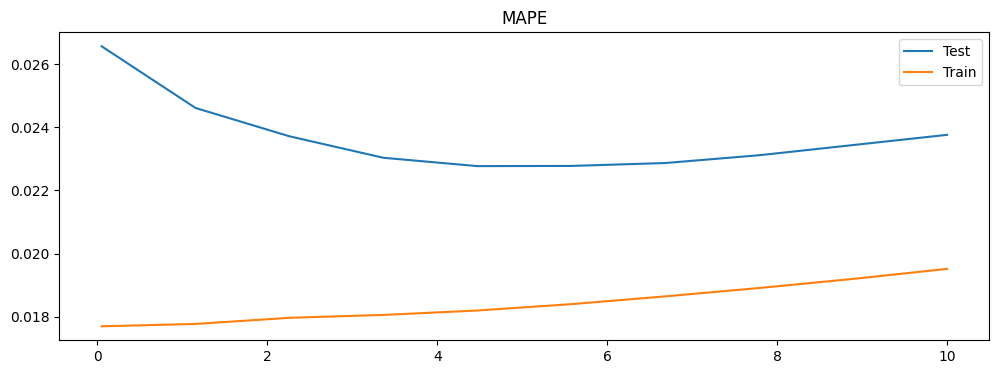

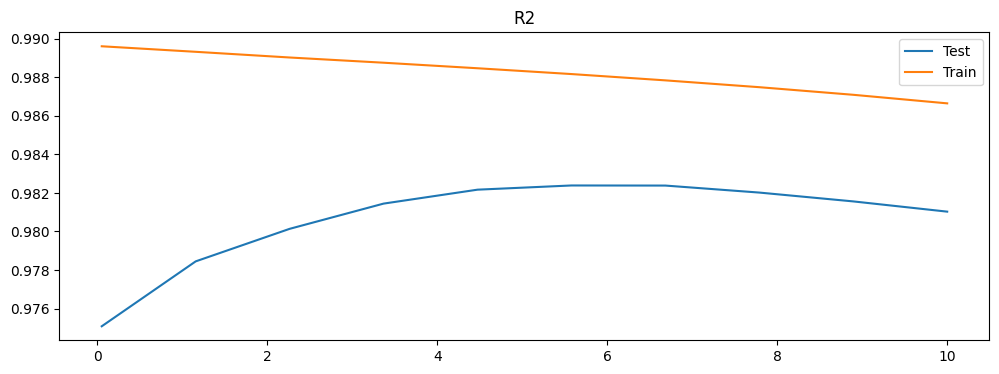

In [165]:
# Ваш код здесь
alpha_list = np.linspace(0.05, 10, 10) 
# создаем пустые списки, в которые будем добавлять результаты 
train_scores_mape = []
test_scores_mape = []
train_scores_r2 = []
test_scores_r2 = []
for alpha in alpha_list:
    lasso = Lasso(alpha=alpha) # создаем объект класса линейная регрессия с L1-регуляризацией
    w_lasso = lasso.fit(X_poly, y) # обучаем модель 
    cv = cross_validate(w_lasso, X_poly, y, scoring=['neg_mean_absolute_percentage_error','r2'], cv=5, return_train_score=True)    # делаем кроссвалидацию 
    #добавляем метрики в списки
    train_scores_mape.append(-cv['train_neg_mean_absolute_percentage_error'].mean())
    test_scores_mape.append(-cv['test_neg_mean_absolute_percentage_error'].mean())
    train_scores_r2.append(cv['train_r2'].mean())
    test_scores_r2.append(cv['test_r2'].mean())

# Пострим график зависимости среднего MAPE на тестовых выборках от alpha 
fig1, ax1 = plt.subplots(figsize=(12, 4)) 
ax1.set_title('MAPE')
ax1.plot(alpha_list, test_scores_mape, label='Test')
ax1.plot(alpha_list, train_scores_mape, label='Train')
ax1.legend()
# Пострим график зависимости среднего R2 на тестовых выборках от alpha 
fig2, ax2 = plt.subplots(figsize=(12, 4)) 
ax2.set_title('R2')
ax2.plot(alpha_list, test_scores_r2, label='Test')
ax2.plot(alpha_list, train_scores_r2, label='Train')
ax2.legend()

lasso = Lasso(alpha=5)
w_lasso = lasso.fit(X_poly, y)
cv_lasso = cross_validate(w_lasso, X_poly, y, scoring=['neg_mean_absolute_percentage_error','r2'], cv=5, return_train_score=True)

print("Метрики для полиномиальной регрессии 3го порядка с L1-регуляризацией при оптимальном alpha=5: ")
print('MAPE на тренировочных фолдах: {:.2f} %'.format(-cv_lasso['train_neg_mean_absolute_percentage_error'].mean()* 100))
print("MAPE на валидационных фолдах: {:.2f} %".format(-cv_lasso['test_neg_mean_absolute_percentage_error'].mean() * 100))
print('R2 на тренировочных фолдах: {:.3f}'.format(cv_lasso['train_r2'].mean()))
print('R2 на валидационных фолдах: {:.3f}'.format(cv_lasso['test_r2'].mean()))

> *Ваши выводы здесь*  
Графики зависимости метрик от значений alpha показывают, что потимальный коэффициент для данной регуляризации в районе 5
L-1 регуляризация повысила точность предсказаний полиномиальной регрессии и на тренировочных и на тестовых фолдах.

### Задание 8.3. (2 балла)

Проделаем то же самое с $L_2$-регуляризацией.

Обучите модель `Ridge` из библиотеки `sklearn` на полученных полиномиальных факторах, предварительно стандартизировав факторы. 

Коэффициент регуляризации (`alpha`) подберите самостоятельно с помощью любого известного вам метода подбора гиперпаметров.

Используя кросс-валидацию оцените среднее значение выбранной вами метрики (или метрик) на тренировочных и валидационных фолдах.

Проинтерпретируйте полученные результаты.

Минимальное MAPE при alpha= 0.01
Метрики для полиномиальной регрессии 3го порядка с L2-регуляризацией при оптимальном alpha=0.01: 
MAPE на тренировочных фолдах: 1.77 %
MAPE на валидационных фолдах: 2.68 %
R2 на тренировочных фолдах: 0.990
R2 на валидационных фолдах: 0.975


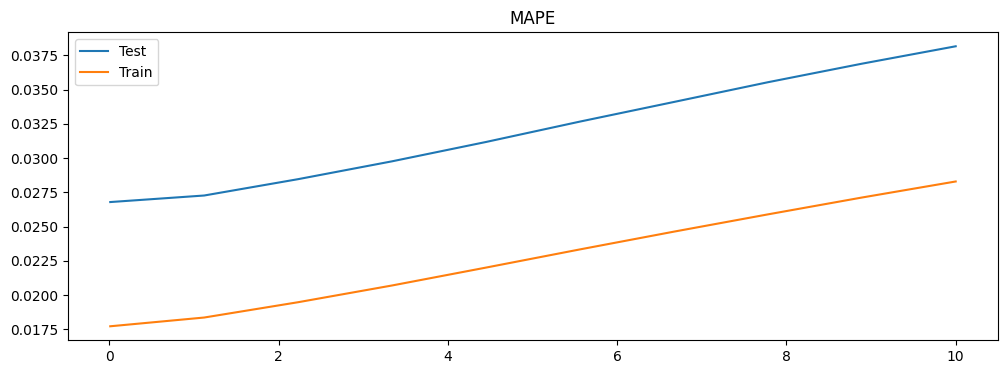

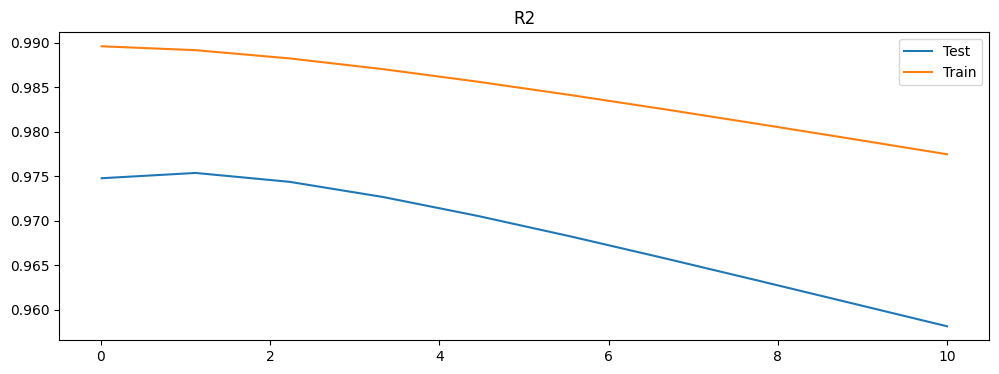

In [166]:
# Ваш код здесь
alpha_list = np.linspace(0.01, 10, 10) 
# создаем пустые списки, в которые будем добавлять результаты 
train_scores_mape = []
test_scores_mape = []
train_scores_r2 = []
test_scores_r2 = []
for alpha in alpha_list:
    ridge = Ridge(alpha=alpha) # создаем объект класса линейная регрессия с L1-регуляризацией
    w_ridge = ridge.fit(X_poly, y) # обучаем модель 
    cv = cross_validate(w_ridge, X_poly, y, scoring=['neg_mean_absolute_percentage_error','r2'], cv=5, return_train_score=True)    # делаем кроссвалидацию 
    #добавляем метрики в списки
    train_scores_mape.append(-cv['train_neg_mean_absolute_percentage_error'].mean())
    test_scores_mape.append(-cv['test_neg_mean_absolute_percentage_error'].mean())
    train_scores_r2.append(cv['train_r2'].mean())
    test_scores_r2.append(cv['test_r2'].mean())

# Пострим график зависимости среднего MAPE на тестовых выборках от alpha 
fig1, ax1 = plt.subplots(figsize=(12, 4)) 
ax1.set_title('MAPE')
ax1.plot(alpha_list, test_scores_mape, label='Test')
ax1.plot(alpha_list, train_scores_mape, label='Train')
ax1.legend()
# Пострим график зависимости среднего R2 на тестовых выборках от alpha 
fig2, ax2 = plt.subplots(figsize=(12, 4)) 
ax2.set_title('R2')
ax2.plot(alpha_list, test_scores_r2, label='Test')
ax2.plot(alpha_list, train_scores_r2, label='Train')
ax2.legend()

alpha = alpha_list[test_scores_mape.index(min(test_scores_mape))]
print("Минимальное MAPE при alpha=", alpha)
ridge = Ridge(alpha=alpha)
w_ridge = ridge.fit(X_poly, y)
cv_ridge = cross_validate(w_ridge, X_poly, y, scoring=['neg_mean_absolute_percentage_error','r2'], cv=5, return_train_score=True)

print("Метрики для полиномиальной регрессии 3го порядка с L2-регуляризацией при оптимальном alpha=0.01: ")
print('MAPE на тренировочных фолдах: {:.2f} %'.format(-cv_ridge['train_neg_mean_absolute_percentage_error'].mean()* 100))
print("MAPE на валидационных фолдах: {:.2f} %".format(-cv_ridge['test_neg_mean_absolute_percentage_error'].mean() * 100))
print('R2 на тренировочных фолдах: {:.3f}'.format(cv_ridge['train_r2'].mean()))
print('R2 на валидационных фолдах: {:.3f}'.format(cv_ridge['test_r2'].mean()))

> *Ваши выводы здесь*  
Метрики ухудшились. Для данной полиномиальной модели L1-регуляция оказалась эффективнее.

**Критерии оценивания:**

- Задание выполнено верно, учтены все условия (**2 балла**): 
    * правильно построена модель полиномиальной регрессии (линейной регрессии на полиномиальных признаках) с регуляризацией (Ridge), учтены условия необходимости масштабирования факторов для построения модели;
    * приведён код для подбора параметра регуляризации (вручную или с помощью библиотечных инструментов);
    * с помощью кросс-валидации оценено среднее значение выбранной студентом метрики (или метрик) на тренировочных и валидационных фолдах (метрика должна быть выбрана корректно).

- Задание выполнено верно, но не учтено одно из условий (**1 балл**).
- Задание выполнено неверно, не учтено несколько условий (**0 баллов**).

### Задание 8.4. (2 балла)

Наконец, настало время комбинировать $L_1$ и $L_2$ -регуляризации.

Обучите модель `ElasticNet` из библиотеки `sklearn` на полученных полиномиальных факторах, предварительно стандартизировав факторы. 

Коэффициенты регуляризации (`alpha` и `l1-ratio`) подберите самостоятельно с помощью любого известного вам метода подбора гиперпаметров.

Используя кросс-валидацию, оцените среднее значение метрики MAPE на тренировочных и валидационных фолдах.

Проинтерпретируйте полученные результаты.

**Критерии оценивания:**

- Задание выполнено верно, учтены все условия (**2 балла**): 
    * правильно построена модель полиномиальной регрессии (линейной регрессии на полиномиальных признаках) с регуляризацией (ElasticNet), учтены условия необходимости масштабирования факторов для построения модели;
    * приведён код для подбора параметра регуляризации (вручную или с помощью библиотечных инструментов);
    * с помощью кросс-валидации оценено среднее значение выбранной студентом метрики (или метрик) на тренировочных и валидационных фолдах (метрика должна быть выбрана корректно).

- Задание выполнено верно, но не учтено одно из условий (**1 балл**).
- Задание выполнено неверно, не учтено несколько условий (**0 баллов**).

In [167]:
# Ваш код здесь
from hyperopt import hp, fmin, tpe, Trials
from sklearn.model_selection import cross_val_score


# зададим пространство поиска коэффициентов регуляризации
space={'alpha': hp.quniform('alpha', 1, 10, 1),
       'l1_ratio': hp.quniform('l1_ratio', 0.1, 1, 0.05)}

def hyperopt_en(params, cv=5, X=X_poly, y=y):
    # функция получает комбинацию гиперпараметров в "params"
    params = {'alpha': int(params['alpha']), 
              'l1_ratio': int(params['l1_ratio'])}
    # используем эту комбинацию для построения модели
    w_en = ElasticNet(**params, max_iter=500, random_state=42)
    # обучаем модель
    w_en.fit(X, y)
    score = cross_val_score(w_en, X, y, cv=5, scoring='neg_mean_absolute_percentage_error', n_jobs=-1).mean()
    
    return -score

trials = Trials()

best_coef=fmin(hyperopt_en, # наша функция 
          space=space, # пространство гиперпараметров
          max_evals=100, # максимальное количество итераций
          trials=trials, # логирование результатов
         )
print("Наилучшие значения гиперпараметров {}".format(best_coef))

w_en = ElasticNet(**best_coef)

cv_en = cross_validate(w_en, X_poly, y, scoring=['neg_mean_absolute_percentage_error','r2'], cv=5, return_train_score=True)

print('MAPE на тренировочных фолдах: {:.2f} %'.format(-cv_en['train_neg_mean_absolute_percentage_error'].mean()* 100))
print("MAPE на валидационных фолдах: {:.2f} %".format(-cv_en['test_neg_mean_absolute_percentage_error'].mean() * 100))
print('R2 на тренировочных фолдах: {:.3f}'.format(cv_en['train_r2'].mean()))
print('R2 на валидационных фолдах: {:.3f}'.format(cv_en['test_r2'].mean()))

TPE is being used as the default algorithm.


  0%|          | 0/100 [00:00<?, ?trial/s, best loss=?]

c:\Users\Talic\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.175e+07, tolerance: 1.958e+04 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(



  1%|          | 1/100 [00:00<01:07,  1.47trial/s, best loss: 0.12660710140576387]

c:\Users\Talic\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.345e+07, tolerance: 1.958e+04 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(



  2%|▏         | 2/100 [00:01<00:55,  1.78trial/s, best loss: 0.11613000268547449]

... (13 outputs left out)

 92%|█████████▏| 92/100 [00:03<00:00, 57.20trial/s, best loss: 0.02276158066543644]

c:\Users\Talic\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.600e+07, tolerance: 1.958e+04 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(

c:\Users\Talic\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.668e+07, tolerance: 1.958e+04 Linear regression models with null weight for the l1 regularization term are more efficiently

100%|██████████| 100/100 [00:03<00:00, 31.48trial/s, best loss: 0.02276158066543644]
Наилучшие значения гиперпараметров {'alpha': np.float64(5.0), 'l1_ratio': np.float64(1.0)}
MAPE на тренировочных фолдах: 1.83 %
MAPE на валидационных фолдах: 2.28 %
R2 на тренировочных фолдах: 0.988
R2 на валидационных фолдах: 0.982


c:\Users\Talic\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.412e+07, tolerance: 1.958e+04 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(

c:\Users\Talic\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.381e+07, tolerance: 1.958e+04 Linear regression models with null weight for the l1 regularization term are more efficiently

> *Ваши выводы здесь*  
Подбор коэффициентом ElasticNet привёл нас к значениям alpha = 5 и l1_ratio=1, что фактически является обычной L1-регуляризацией. Значения метрик так же соответствуют регуляризации Lasso.

### Задание 8.5. (1 балл)

Завершением вашей работы будет сводная таблица результатов, которую вы представите на презентации заказчику Василию.

Составьте таблицу (DataFrame) со следующими столбцами (имена столбцов выберите самостоятельно):
* Наименование модели.
* Гиперпараметры (коэффициенты регуляризации, если таковые имеются), если нет — оставьте ячейку пустой.
* Использовались ли полиномиальные признаки при построении модели (Да/Нет или True/False).
* Значение выбранной метрики на тренировочных фолдах при кросс-валидации модели.
* Значение выбранной метрики на валидационных фолдах при кросс-валидации модели.

Сделайте финальный вывод по проделанной работе. Какая линейная модель из тех, что мы рассмотрели, показала наилучший результат с точки зрения качества на валидационных фолдах, а также с точки зрения переобученности?

**Критерии оценивания:**

- Задание выполнено верно, учтены все условия (**1 балл**): 
    * верно составлена сводная таблица итоговых результатов построенных ранее моделей с указанными в задании столбцами;
    * приведены итоговые выводы по проделанной работе, указано, какая из рассмотренных моделей показала наилучший результат.

- Задание выполнено неверно, не учтено одно или несколько условий (**0 баллов**).

In [169]:
# Ваш код здесь
#columns = ['Наименование модели', 'Гиперпараметры', 'Полиномиальные признаки', 'MAPE (Train) ', 'MAPE (Test)', 'R2 (Train)', 'R2 (Test)']

result = pd.DataFrame()
#result = result.append()
dict = {'Наименование модели': ['Линейная регрессия по всем признакам (numpy)', 
                                'Линейная регрессия по отобранным признакам (numpy)', 
                                'Линейная регрессия по отобранным признакам (sklearn)', 
                                'Полиномиальная регрессия', 
                                'Полиномиальная регрессия - L1-регуляризация', 
                                'Полиномиальная регрессия - L2-регуляризация',
                                'Полиномиальная регрессия - ElasticNet'],
        'Гиперпараметры': ['','','', '', 'alpha=5', 'alpha=0.01', 'alpha=5 / l1_score=1'],
        'Полиномиальные признаки': ['False', 'False','False', 'True', 'True', 'True', 'True'],
        'MAPE (Train)': [3.63, 4.04, 4.04, 1.77, 1.83, 1.77, 1.83],
        'MAPE (Test)': ['', '', '', 2.68, 2.28, 2.68, 2.28],
        'R2 (Train)': [0.960, 0.945, 0.945, 0.990, 0.988, 0.990, 0.988],
        'R2 (Test)': ['', '', '', 0.975, 0.982, 0.975, 0.982]
        }

result = pd.DataFrame.from_dict(dict)

display(result)

,Наименование модели,Гиперпараметры,Полиномиальные признаки,MAPE (Train),MAPE (Test),R2 (Train),R2 (Test)
0,Линейная регрессия по всем признакам (numpy),,False,3.63,,0.960,
1,Линейная регрессия по отобранным признакам (nu...,,False,4.04,,0.945,
2,Линейная регрессия по отобранным признакам (sk...,,False,4.04,,0.945,
3,Полиномиальная регрессия,,True,1.77,2.68,0.990,0.975
4,Полиномиальная регрессия - L1-регуляризация,alpha=5,True,1.83,2.28,0.988,0.982
5,Полиномиальная регрессия - L2-регуляризация,alpha=0.01,True,1.77,2.68,0.990,0.975
6,Полиномиальная регрессия - ElasticNet,alpha=5 / l1_score=1,True,1.83,2.28,0.988,0.982


> *Ваши выводы здесь*  
Лучший результат показала линейная модель с полиномиальными признаками 3-го порядка и L1-регуляризацией. У неё и лучшие метрики на валидационных фолдах и минимальная разница этих метрик с метриками полученными на тренировочных фолдах, что говорит, о том, что у данной модели меньше всего проблем с переобученностью. Модель с регуляризацией ElasticNet показала аналогичный результат по причине того, что в результате подбора коэффициентов l1-score получился равным 1, что фактически и привело нас к обычной L1-регуляризации вместо комбинированной.